# Sparse PANN — Selecting the sparsity coefficient ρ

Standalone experiment using the **unchanged synthetic Gent data-generation code** and **SparsePANN architecture** from the four-model notebook. Sweep ρ, compare stress and energy RMSE, and inspect sparsity. The full sweep can be computationally expensive (50,000 observations and 10,000 epochs per candidate).

**Selection:** choose ρ using validation stress **and** validation energy error (normalized by fixed Gent reference scales), optionally restricting active coefficients. **Extrapolation is held out for reporting only**, not for choosing ρ. Training fits **stress only** plus the sparsity penalty; the energy reference is used for evaluation/model selection, not added to the training loss.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import time
import copy

# Same hyperparameters as original notebook
mu = 0.8
jm = 40.0
Identity = torch.eye(3)
num_samples = 50000
lamda_min, lamda_max = 1.0, 4.0
eta_min, eta_max = 0.005, 0.03
m = 32
learning_rate = 0.01
num_epochs = 10000

torch.manual_seed(42)  # Reproducible comparison
import numpy as np
import pandas as pd
import seaborn as sns

# Same hard-concrete settings as uploaded sparsification notebook
beta, gamma, zeta, rho = 2/3, -0.1, 1.1, 3.5
log_interval = 100

# Candidate rho values; include original rho=3.5
rho_values = [0.0, 0.01, 0.1, 0.5, 1.0, 3.5, 7.0, 15.0]
# For a faster exploratory run, change num_epochs temporarily; restore 10000 for final analysis.


In [2]:
# Original Gent stress and noise generation (unchanged equations)
def gent_stress_function(lamda, mu, jm):
    I1 = lamda**2 + 2/lamda
    stress = mu * (lamda - 1/lamda**2) / (1 - (I1 - 3)/jm)
    return stress

def deformation_gradient(lamda):
    diagonal_values = torch.stack([
        lamda,
        lamda**(-0.5),
        lamda**(-0.5)
    ], dim=-1)
    return torch.diag_embed(diagonal_values)

def frobenius_norm(F):
    return torch.sqrt(torch.sum((F - Identity)**2, dim=(-2, -1)))

def add_noise(P_true_train, eta_min, eta_max, lamda):
    P_char = torch.max(torch.abs(P_true_train))
    noise_sd_min = eta_min * P_char
    noise_sd_max = eta_max * P_char
    F = deformation_gradient(lamda)
    F_lambdamax = deformation_gradient(torch.max(lamda))
    q = 2.0
    t = frobenius_norm(F)
    ksy = torch.randn_like(P_true_train)
    conditional_noise_variance = torch.square(noise_sd_min) + (torch.square(noise_sd_max) - torch.square(noise_sd_min)) * ((t / frobenius_norm(F_lambdamax))**q)
    noise = torch.sqrt(conditional_noise_variance) * ksy
    return noise, conditional_noise_variance

def generate_synthetic_data(num_samples, lamda_min, lamda_max, eta_min, eta_max):
    lamda_train = torch.linspace(lamda_min, lamda_max, num_samples)
    I1_train = lamda_train**2 + 2/lamda_train
    P_true_train = gent_stress_function(lamda_train, mu, jm)
    noise, conditional_noise_variance = add_noise(P_true_train, eta_min, eta_max, lamda_train)
    Y_train = P_true_train + noise
    Y_train = Y_train.reshape(-1, 1)
    lamda_train = lamda_train.reshape(-1, 1)
    I1_train = I1_train.reshape(-1, 1)
    x = torch.cat((lamda_train, I1_train, Y_train), dim=1)
    return x, conditional_noise_variance

x, conditional_noise_variance = generate_synthetic_data(
    num_samples=50000, lamda_min=1.0, lamda_max=4.0,
    eta_min=0.005, eta_max=0.03
)


In [3]:
indices = torch.randperm(len(x))
n_train = int(0.8 * len(x))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

x_train = x[train_idx]
x_val = x[val_idx]
variance_train = conditional_noise_variance[train_idx].reshape(-1, 1)
variance_val = conditional_noise_variance[val_idx].reshape(-1, 1)

print('Training samples:', len(x_train))
print('Validation samples:', len(x_val))


Training samples: 40000
Validation samples: 10000


In [4]:
import math
# Sparse PANN: original energy architecture with Hard-Concrete gates on a, c, w, b.
# Deterministic gates are used at evaluation; random gates only during training.
class SparsePANN(nn.Module):
    def __init__(self, m=32, beta=2/3, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.a = nn.Parameter(torch.randn(1))
        self.c = nn.Parameter(torch.randn(m))
        self.w = nn.Parameter(torch.randn(m))
        self.b = nn.Parameter(torch.randn(m))
        self.log_alpha_a = nn.Parameter(torch.randn(1))
        self.log_alpha_c = nn.Parameter(torch.randn(m))
        self.log_alpha_w = nn.Parameter(torch.randn(m))
        self.log_alpha_b = nn.Parameter(torch.randn(m))
        self.beta, self.gamma, self.zeta = beta, gamma, zeta

    def gate_logits(self):
        return [self.log_alpha_a, self.log_alpha_c,
                self.log_alpha_w, self.log_alpha_b]

    def gate(self, log_alpha, stochastic=True):
        if stochastic:
            u = torch.rand_like(log_alpha).clamp(1e-6, 1-1e-6)
            s = torch.sigmoid((torch.log(u) - torch.log1p(-u) + log_alpha) / self.beta)
        else:
            s = torch.sigmoid(log_alpha)
        return (s * (self.zeta - self.gamma) + self.gamma).clamp(0, 1)

    def forward(self, I1, stochastic=True):
        ga, gc, gw, gb = [self.gate(v, stochastic) for v in self.gate_logits()]
        a = F.softplus(self.a) * ga
        c = F.softplus(self.c) * gc
        w = F.softplus(self.w) * gw
        b = self.b * gb
        x = I1 - 3
        return a*x + (c * (F.softplus(x*w + b) - F.softplus(b))).sum(dim=-1, keepdim=True)

    def expected_active(self):
        offset = self.beta * np.log(-self.gamma/self.zeta)
        return sum(torch.sigmoid(v-offset).sum() for v in self.gate_logits())

    def active_count(self):
        return sum(int((self.gate(v, False)>0).sum().item()) for v in self.gate_logits())




## Evaluation metrics and rho-selection policy

Stress RMSE compares predictions with noisy held-out stress observations (and clean Gent stress separately). Energy RMSE compares predicted energy with **analytical Gent energy**, with ψ(3)=0 for both. The joint score uses the two RMSEs divided by *fixed reference ranges* (not rho-dependent scales), giving them equal weight by default. You may adjust weights to reflect scientific priorities.

`active_count()` counts individual gated coefficients, not necessarily entire removed neurons. We also report effective active hidden terms (requiring nonzero c and w gates).

In [5]:
def gent_energy(I1):
    return -(mu * jm / 2.0) * torch.log1p(-(I1 - 3.0) / jm)

# Fixed validation scales for dimensionless, equally weighted selection
with torch.no_grad():
    val_lam = x_val[:, 0:1]
    stress_scale = (gent_stress_function(val_lam, mu, jm).max() -
                    gent_stress_function(val_lam, mu, jm).min()).item()
    energy_scale = (gent_energy(x_val[:, 1:2]).max() -
                    gent_energy(x_val[:, 1:2]).min()).item()

stress_weight, energy_weight = 0.5, 0.5
assert stress_scale > 0 and energy_scale > 0

# Choose a cap if you REQUIRE a certain complexity, otherwise None.
max_active_coefficients = None

def sparse_stress(model, lam, stochastic=False, create_graph=False):
    I1 = (lam**2 + 2.0 / lam).detach().requires_grad_(True)
    psi = model(I1, stochastic=stochastic)
    derivative = torch.autograd.grad(psi.sum(), I1, create_graph=create_graph)[0]
    return 2.0 * (lam - lam.pow(-2)) * derivative

def measure(model, data):
    model.eval()
    lam = data[:, 0:1]
    # Gradients must remain enabled for the derivative dψ/dI1.
    with torch.enable_grad():
        pred_stress = sparse_stress(model, lam, stochastic=False)
    with torch.no_grad():
        pred_energy = model(data[:, 1:2], stochastic=False)
        target_energy = gent_energy(data[:, 1:2])
        clean_stress = gent_stress_function(lam, mu, jm)
        stress_rmse = torch.mean((pred_stress.detach() - data[:, 2:3])**2).sqrt().item()
        clean_stress_rmse = torch.mean((pred_stress.detach() - clean_stress)**2).sqrt().item()
        energy_rmse = torch.mean((pred_energy - target_energy)**2).sqrt().item()
        expected_active = model.expected_active().item()
        active = model.active_count()
        gates_c = model.gate(model.log_alpha_c, stochastic=False)
        gates_w = model.gate(model.log_alpha_w, stochastic=False)
        active_terms = int(((gates_c > 0) & (gates_w > 0)).sum().item())
    score = stress_weight * stress_rmse / stress_scale + energy_weight * energy_rmse / energy_scale
    return dict(stress_rmse=stress_rmse, clean_stress_rmse=clean_stress_rmse,
                energy_rmse=energy_rmse, score=score, active=active,
                expected_active=expected_active, active_terms=active_terms)


## Train one independent Sparse PANN per ρ (same initialization, same data)

In [6]:
# Use exactly the same initial weights and gate logits for all rho values.
torch.manual_seed(42)
initial_model = SparsePANN(m=m, beta=beta, gamma=gamma, zeta=zeta)
initial_state = copy.deepcopy(initial_model.state_dict())

sweep_rows = []
sweep_histories = {}
best_models = {}

for rho_candidate in rho_values:
    # Reseed so stochastic gate draws are reproducible across rho runs.
    torch.manual_seed(2026)
    model = SparsePANN(m=m, beta=beta, gamma=gamma, zeta=zeta)
    model.load_state_dict(copy.deepcopy(initial_state))
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    best_score = float('inf')
    best_state = None
    best_epoch = None
    history = []
    t0 = time.perf_counter()

    for epoch in range(1, num_epochs + 1):
        model.train()
        optimizer.zero_grad()
        pred = sparse_stress(model, x_train[:, 0:1], stochastic=True, create_graph=True)
        fit_loss = ((pred - x_train[:, 2:3]).square() / variance_train).mean()
        loss = fit_loss + rho_candidate * model.expected_active()
        loss.backward()
        optimizer.step()

        if epoch == 1 or epoch % log_interval == 0 or epoch == num_epochs:
            val_metrics = measure(model, x_val)
            history.append(dict(epoch=epoch, **val_metrics))
            if val_metrics['score'] < best_score:
                best_score = val_metrics['score']
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    train_metrics = measure(model, x_train)
    val_metrics = measure(model, x_val)
    sweep_rows.append(dict(rho=rho_candidate, best_epoch=best_epoch,
                           train_stress_rmse=train_metrics['stress_rmse'],
                           train_energy_rmse=train_metrics['energy_rmse'],
                           **{('val_' + k): v for k, v in val_metrics.items()},
                           seconds=time.perf_counter() - t0))
    sweep_histories[rho_candidate] = pd.DataFrame(history)
    best_models[rho_candidate] = model
    print(f"rho={rho_candidate:g} | epoch={best_epoch} | "
          f"stress={val_metrics['stress_rmse']:.5f} | "
          f"energy={val_metrics['energy_rmse']:.5f} | "
          f"active={val_metrics['active']} | score={val_metrics['score']:.5f}")

sweep_df = pd.DataFrame(sweep_rows).sort_values('rho').reset_index(drop=True)
print(sweep_df[['rho','best_epoch','val_stress_rmse','val_energy_rmse',
                'val_active','val_active_terms','val_score']].to_string(index=False))


rho=0 | epoch=10000 | stress=0.14635 | energy=0.03131 | active=94 | score=0.01777
rho=0.01 | epoch=10000 | stress=0.14501 | energy=0.03248 | active=92 | score=0.01772
rho=0.1 | epoch=10000 | stress=0.16692 | energy=0.03501 | active=80 | score=0.02021
rho=0.5 | epoch=7100 | stress=0.18732 | energy=0.04621 | active=71 | score=0.02321
rho=1 | epoch=6800 | stress=0.17901 | energy=0.07231 | active=67 | score=0.02432
rho=3.5 | epoch=9700 | stress=0.18539 | energy=0.06636 | active=12 | score=0.02453
rho=7 | epoch=7300 | stress=0.18007 | energy=0.09893 | active=22 | score=0.02645
rho=15 | epoch=6500 | stress=0.18418 | energy=0.09861 | active=14 | score=0.02685
  rho  best_epoch  val_stress_rmse  val_energy_rmse  val_active  val_active_terms  val_score
 0.00       10000         0.146348         0.031305          94                29   0.017768
 0.01       10000         0.145013         0.032477          92                29   0.017716
 0.10       10000         0.166920         0.035011         

## Figure 1 — Stress and energy validation RMSE versus ρ; Figure 2 — sparsity versus ρ

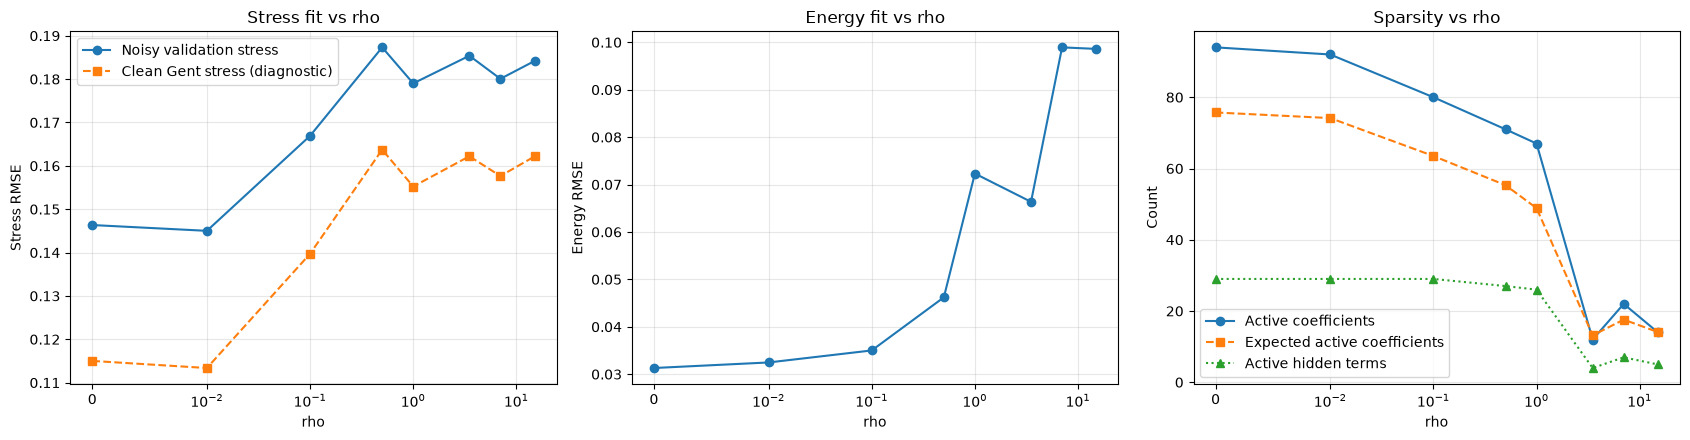

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(sweep_df.rho, sweep_df.val_stress_rmse, 'o-', label='Noisy validation stress')
axes[0].plot(sweep_df.rho, sweep_df.val_clean_stress_rmse, 's--', label='Clean Gent stress (diagnostic)')
axes[0].set(title='Stress fit vs rho', xlabel='rho', ylabel='Stress RMSE')
axes[0].legend()
axes[1].plot(sweep_df.rho, sweep_df.val_energy_rmse, 'o-')
axes[1].set(title='Energy fit vs rho', xlabel='rho', ylabel='Energy RMSE')
axes[2].plot(sweep_df.rho, sweep_df.val_active, 'o-', label='Active coefficients')
axes[2].plot(sweep_df.rho, sweep_df.val_expected_active, 's--', label='Expected active coefficients')
axes[2].plot(sweep_df.rho, sweep_df.val_active_terms, '^:', label='Active hidden terms')
axes[2].set(title='Sparsity vs rho', xlabel='rho', ylabel='Count')
axes[2].legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.set_xscale('symlog', linthresh=0.01)
plt.tight_layout()
plt.show()


## Select best ρ using joint validation score, optionally with a sparsity constraint

Best rho by joint validation stress+energy score: 0.01
best_epoch          10000.000000
val_stress_rmse         0.145013
val_energy_rmse         0.032477
val_score               0.017716
val_active             92.000000
val_active_terms       29.000000
Name: 1, dtype: float64


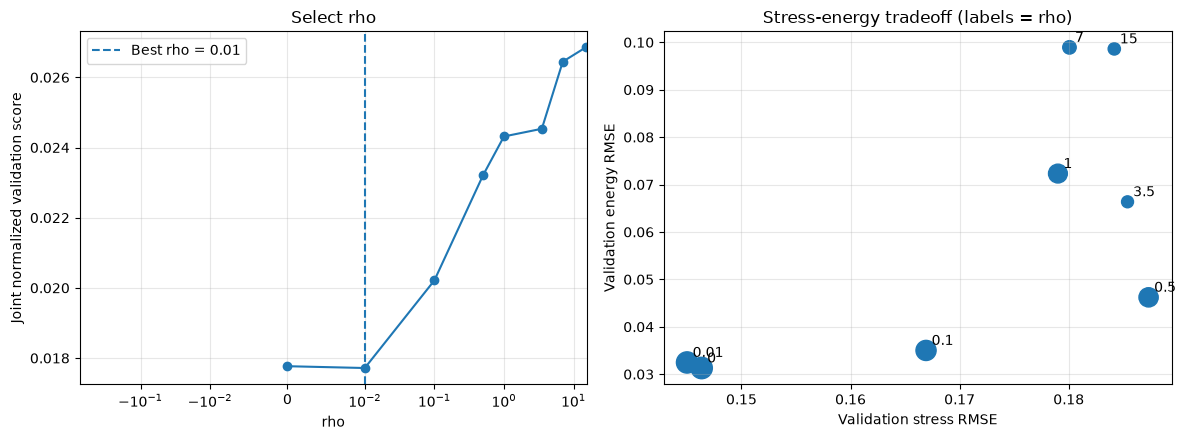

In [8]:
eligible = sweep_df.copy()
if max_active_coefficients is not None:
    eligible = eligible[eligible.val_active <= max_active_coefficients]
    if eligible.empty:
        raise ValueError('No rho satisfies the active-parameter limit. Relax the limit.')

best_row = eligible.loc[eligible.val_score.idxmin()]
best_rho = float(best_row.rho)
best_model = best_models[best_rho]
print(f'Best rho by joint validation stress+energy score: {best_rho:g}')
print(best_row[['best_epoch', 'val_stress_rmse', 'val_energy_rmse',
                'val_score', 'val_active', 'val_active_terms']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(sweep_df.rho, sweep_df.val_score, 'o-')
axes[0].axvline(best_rho, linestyle='--', label=f'Best rho = {best_rho:g}')
axes[0].set(xlabel='rho', ylabel='Joint normalized validation score', title='Select rho')
axes[0].set_xscale('symlog', linthresh=0.01)
axes[0].legend()
axes[1].scatter(sweep_df.val_stress_rmse, sweep_df.val_energy_rmse,
                s=50 + 2 * sweep_df.val_active)
for row in sweep_df.itertuples():
    axes[1].annotate(f'{row.rho:g}', (row.val_stress_rmse, row.val_energy_rmse),
                     xytext=(4,4), textcoords='offset points')
axes[1].set(xlabel='Validation stress RMSE', ylabel='Validation energy RMSE',
            title='Stress-energy tradeoff (labels = rho)')
for ax in axes: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Figures — Stress and energy curves at the selected ρ (train region and extrapolation)

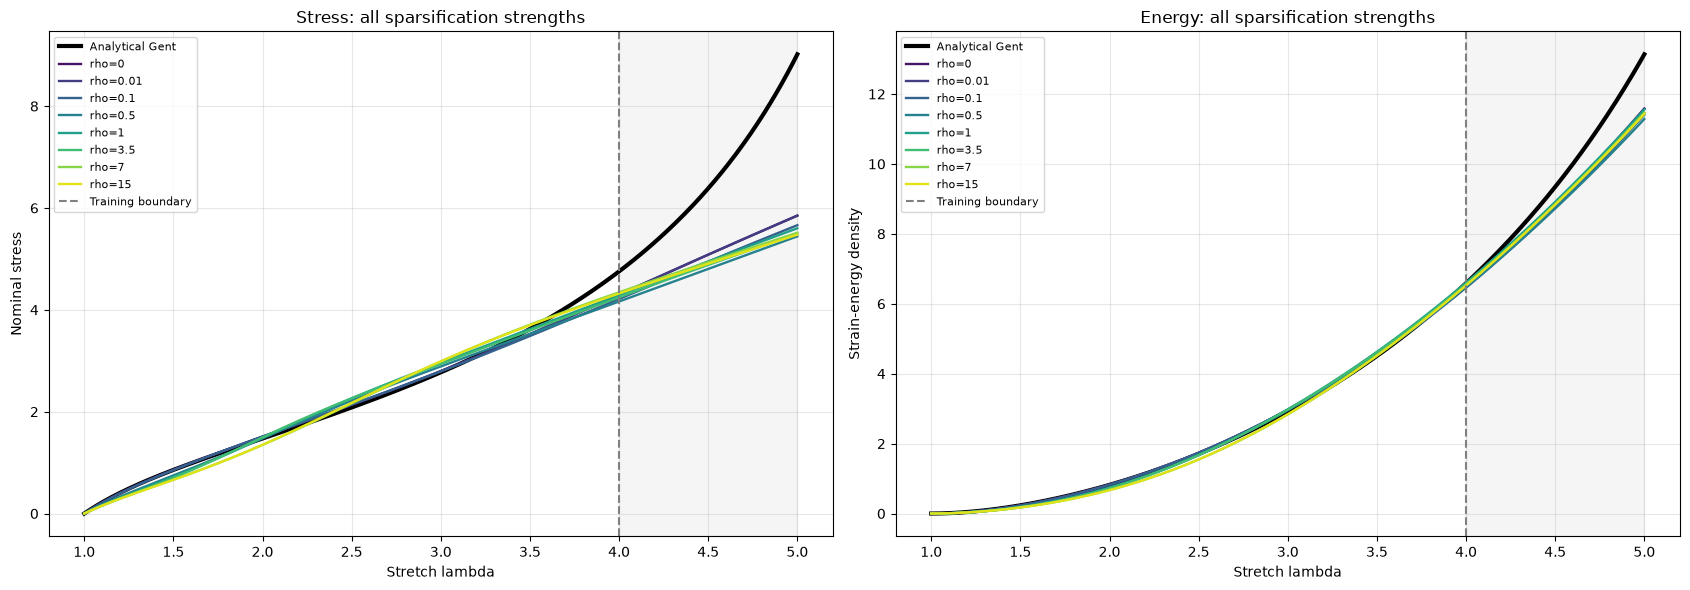

Extrapolation errors (report only; NOT used to select rho):
      rho  extrap_stress_rmse  extrap_energy_rmse
 0.000000            1.666605            0.742216
 0.010000            1.666675            0.734860
 0.100000            1.801188            0.843077
 0.500000            1.949152            0.897189
 1.000000            1.815604            0.715960
 3.500000            1.886551            0.782941
 7.000000            1.848069            0.774258
15.000000            1.877365            0.795118


In [9]:
# Every rho: Gent stress and energy curves + extrapolation errors.
# Models are already saved by the sweep in best_models[rho].
lamda_plot = torch.linspace(1.0, 5.0, 500).reshape(-1, 1)
I1_plot = lamda_plot**2 + 2.0 / lamda_plot
x_plot = lamda_plot[:, 0].numpy()
with torch.no_grad():
    P_ref = gent_stress_function(lamda_plot, mu, jm).detach().numpy().ravel()
    E_ref = gent_energy(I1_plot).detach().numpy().ravel()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].plot(x_plot, P_ref, color='black', linewidth=3, label='Analytical Gent')
axes[1].plot(x_plot, E_ref, color='black', linewidth=3, label='Analytical Gent')
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(best_models)))
mask = x_plot > 4.0
extrap_rows = []

for color, (rho_candidate, model) in zip(colors, sorted(best_models.items())):
    model.eval()
    with torch.enable_grad():
        P_pred = sparse_stress(model, lamda_plot, stochastic=False).detach().numpy().ravel()
    with torch.no_grad():
        E_pred = model(I1_plot, stochastic=False).detach().numpy().ravel()
    axes[0].plot(x_plot, P_pred, color=color, linewidth=1.7,
                 label=f'rho={rho_candidate:g}')
    axes[1].plot(x_plot, E_pred, color=color, linewidth=1.7,
                 label=f'rho={rho_candidate:g}')
    extrap_rows.append(dict(rho=rho_candidate,
                            extrap_stress_rmse=np.sqrt(np.mean((P_pred[mask]-P_ref[mask])**2)),
                            extrap_energy_rmse=np.sqrt(np.mean((E_pred[mask]-E_ref[mask])**2))))

for ax, title, ylabel in zip(axes,
    ['Stress: all sparsification strengths', 'Energy: all sparsification strengths'],
    ['Nominal stress', 'Strain-energy density']):
    ax.axvspan(4.0, 5.0, color='gray', alpha=0.08)
    ax.axvline(4.0, color='gray', linestyle='--', label='Training boundary')
    ax.set(xlabel='Stretch lambda', ylabel=ylabel, title=title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

extrap_df = pd.DataFrame(extrap_rows).sort_values('rho')
print('Extrapolation errors (report only; NOT used to select rho):')
print(extrap_df.to_string(index=False, float_format=lambda v: f'{v:.6f}'))


## Sparsification diagnostics for **every** rho

Plot the **expected number of active coefficients**, deterministic **nonzero gates**, and **effective energy terms** for each trained Sparse PANN. The four parameter groups are `a`, `c`, `w`, and `b`. A neuron contributes an energy term only if both its `c` and `w` gates are nonzero. Hard-Concrete gate values are deterministic at evaluation; counts are descriptive rather than proof of minimality.

  rho  expected_active  active_gates  effective_terms  active_a  active_c  active_w  active_b
 0.00        75.726959            94               29         1        32        29        32
 0.01        74.151909            92               29         1        32        29        30
 0.10        63.507362            80               29         1        32        29        18
 0.50        55.320126            71               27         1        31        28        11
 1.00        48.875645            67               26         1        29        27        10
 3.50        13.165185            12                4         1         7         4         0
 7.00        17.586613            22                7         1        12         9         0
15.00        14.085917            14                5         1         8         5         0


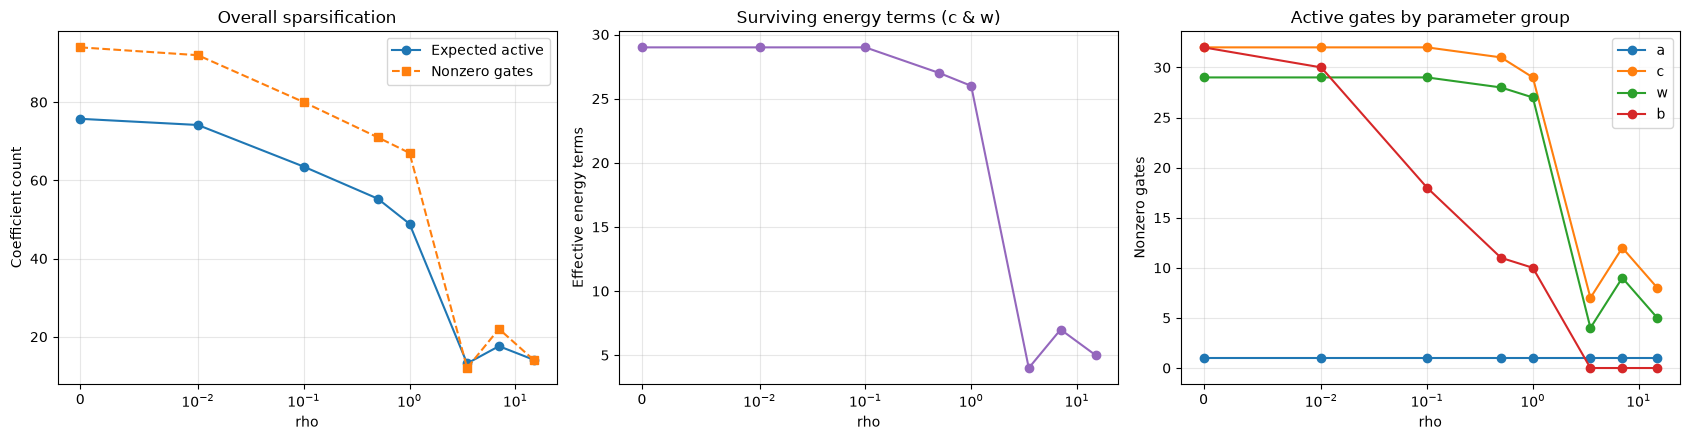

In [10]:
# Inspect the sparsity of the *best validation checkpoint* at each rho.
sparsity_rows = []
gate_rows = []
for rho_candidate, model in sorted(best_models.items()):
    model.eval()
    with torch.no_grad():
        groups = {
            'a': model.gate(model.log_alpha_a, stochastic=False),
            'c': model.gate(model.log_alpha_c, stochastic=False),
            'w': model.gate(model.log_alpha_w, stochastic=False),
            'b': model.gate(model.log_alpha_b, stochastic=False),
        }
        row = {'rho': rho_candidate, 'expected_active': model.expected_active().item(),
               'active_gates': sum(int((g > 0).sum()) for g in groups.values()),
               'effective_terms': int(((groups['c'] > 0) & (groups['w'] > 0)).sum())}
        for group_name, gates in groups.items():
            row[f'active_{group_name}'] = int((gates > 0).sum())
            for neuron_idx, gate in enumerate(gates.flatten().cpu().numpy()):
                gate_rows.append({'rho': rho_candidate, 'group': group_name,
                                  'index': neuron_idx, 'gate': float(gate)})
        sparsity_rows.append(row)
sparsity_df = pd.DataFrame(sparsity_rows)
gates_df = pd.DataFrame(gate_rows)
print(sparsity_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(sparsity_df.rho, sparsity_df.expected_active, 'o-', label='Expected active')
axes[0].plot(sparsity_df.rho, sparsity_df.active_gates, 's--', label='Nonzero gates')
axes[0].set(ylabel='Coefficient count', title='Overall sparsification')
axes[0].legend()
axes[1].plot(sparsity_df.rho, sparsity_df.effective_terms, 'o-', color='tab:purple')
axes[1].set(ylabel='Effective energy terms', title='Surviving energy terms (c & w)')
for group_name in ['a', 'c', 'w', 'b']:
    axes[2].plot(sparsity_df.rho, sparsity_df[f'active_{group_name}'], 'o-', label=group_name)
axes[2].set(ylabel='Nonzero gates', title='Active gates by parameter group')
axes[2].legend()
for ax in axes:
    ax.set_xlabel('rho')
    ax.set_xscale('symlog', linthresh=0.01)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


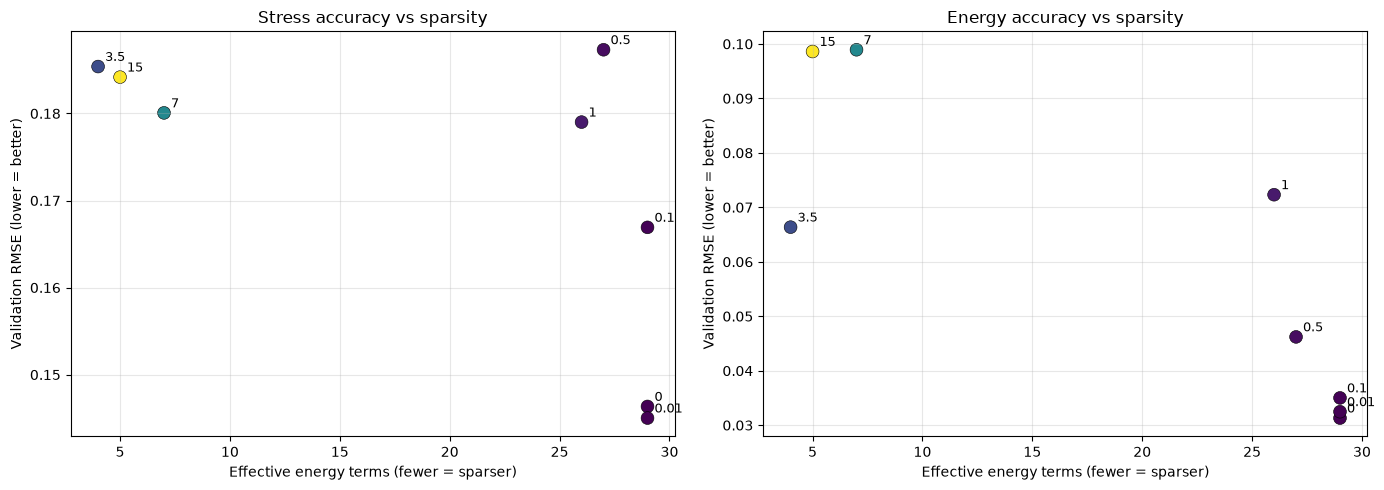

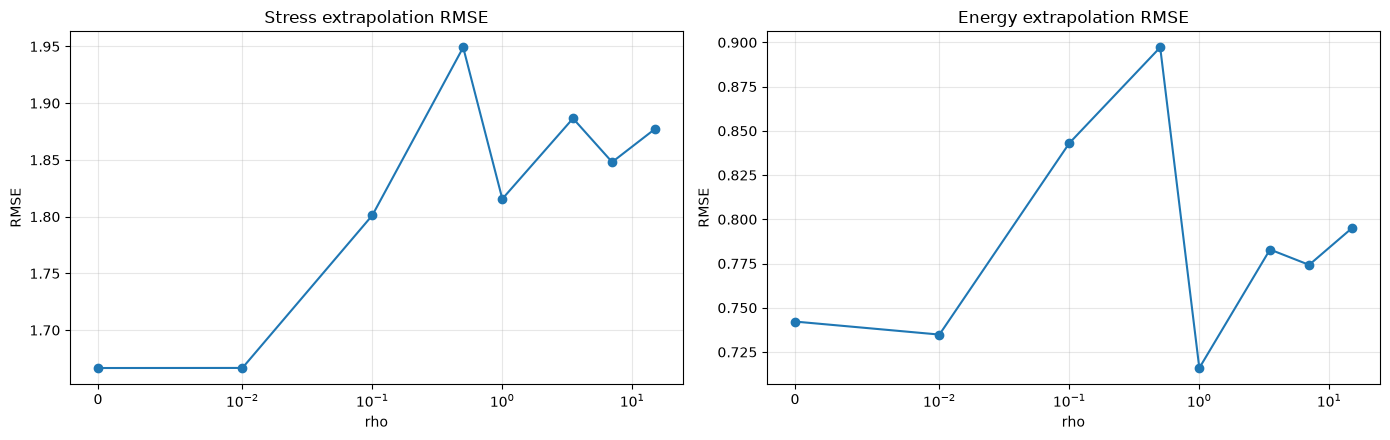

In [11]:
# Sparsification-versus-fit: the central model-selection tradeoff.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
merged = sweep_df.merge(sparsity_df[['rho', 'expected_active', 'active_gates', 'effective_terms']], on='rho')
for ax, error_col, title in [
    (axes[0], 'val_stress_rmse', 'Stress accuracy vs sparsity'),
    (axes[1], 'val_energy_rmse', 'Energy accuracy vs sparsity')]:
    ax.scatter(merged.effective_terms, merged[error_col], s=85, c=merged.rho,
               cmap='viridis', edgecolor='black', linewidth=0.4)
    for row in merged.itertuples():
        ax.annotate(f'{row.rho:g}', (row.effective_terms, getattr(row, error_col)),
                    xytext=(5, 4), textcoords='offset points', fontsize=9)
    ax.set(xlabel='Effective energy terms (fewer = sparser)',
           ylabel='Validation RMSE (lower = better)', title=title)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show extrapolation metrics separately. Never tune rho on these test values.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, title in zip(axes,
    ['extrap_stress_rmse', 'extrap_energy_rmse'],
    ['Stress extrapolation RMSE', 'Energy extrapolation RMSE']):
    ax.plot(extrap_df.rho, extrap_df[col], 'o-')
    ax.set(xlabel='rho', ylabel='RMSE', title=title)
    ax.set_xscale('symlog', linthresh=0.01)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Training trajectories and final comparison heatmap

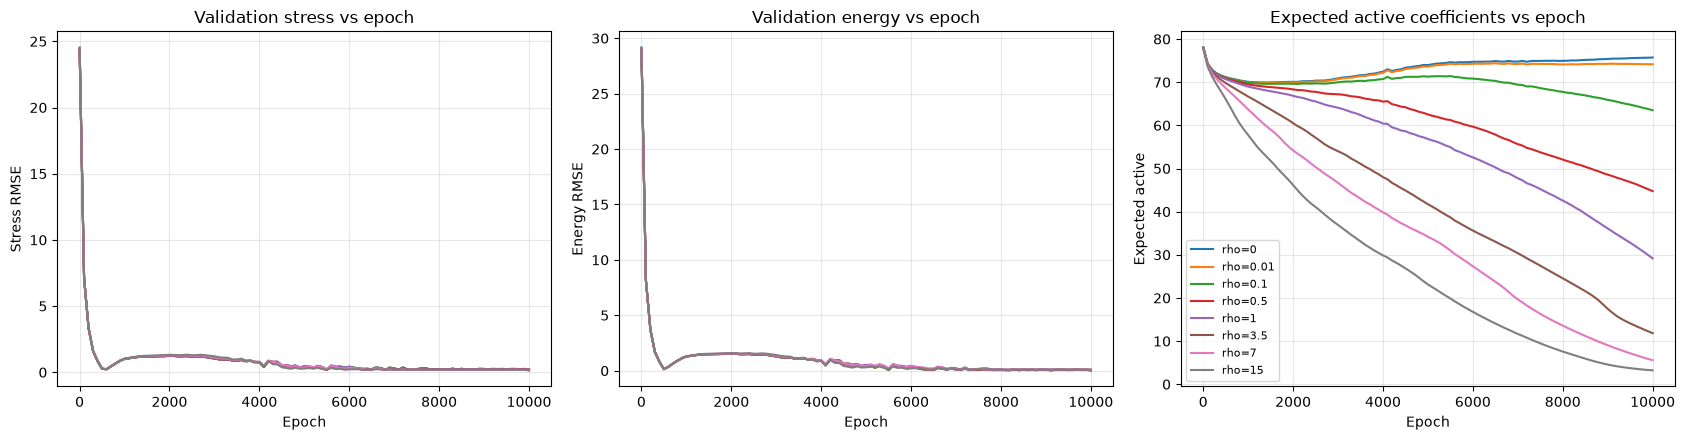

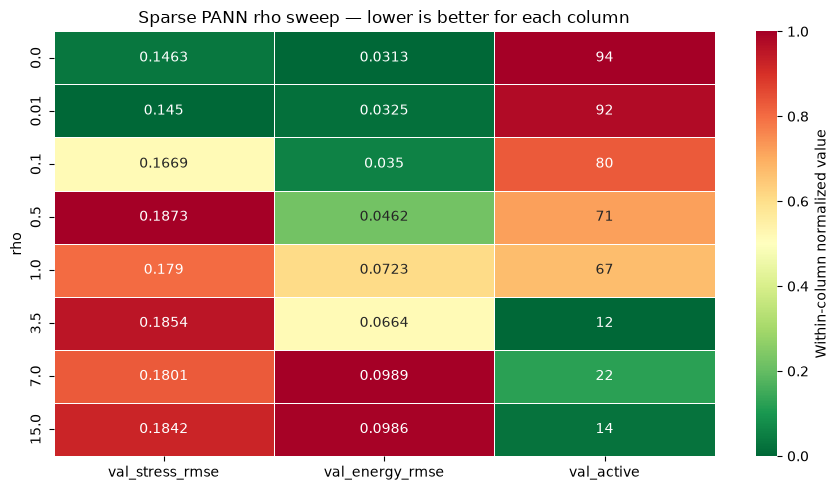

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for rho_candidate in rho_values:
    h = sweep_histories[rho_candidate]
    axes[0].plot(h.epoch, h.stress_rmse, label=f'rho={rho_candidate:g}')
    axes[1].plot(h.epoch, h.energy_rmse, label=f'rho={rho_candidate:g}')
    axes[2].plot(h.epoch, h.expected_active, label=f'rho={rho_candidate:g}')
axes[0].set(title='Validation stress vs epoch', ylabel='Stress RMSE', xlabel='Epoch')
axes[1].set(title='Validation energy vs epoch', ylabel='Energy RMSE', xlabel='Epoch')
axes[2].set(title='Expected active coefficients vs epoch', ylabel='Expected active', xlabel='Epoch')
for ax in axes: ax.grid(True, alpha=0.3)
axes[2].legend(loc='best', fontsize=8)
plt.tight_layout()
plt.show()

heat = sweep_df.set_index('rho')[['val_stress_rmse','val_energy_rmse','val_active']]
# Normalize columns for color comparison, annotate with original values.
normalized = (heat - heat.min()) / (heat.max() - heat.min()).replace(0, 1)
plt.figure(figsize=(9, 5))
sns.heatmap(normalized, annot=heat.round(4).astype(str), fmt='', cmap='RdYlGn_r',
            linewidths=0.7, cbar_kws={'label':'Within-column normalized value'})
plt.title('Sparse PANN rho sweep — lower is better for each column')
plt.ylabel('rho')
plt.tight_layout()
plt.show()


### Interpretation

- The lowest RMSE and the sparsest network are often attained at **different rho values**. There is no unique best rho without a stated tradeoff.
- The selected rho minimizes a **joint validation** score; if interpretability/sparsity is critical, set `max_active_coefficients` or examine the Pareto tradeoff.
- Because the data are synthetic, analytical Gent energy can be evaluated exactly. For real experiments without energy labels, this energy-based rho selection would require a different independent energy reference or physics criterion.
- A single random seed is not enough for robust claims; repeat the sweep over multiple seeds, reporting mean and variability.
- Do not use extrapolation errors to select rho if extrapolation is meant to remain an unbiased test.
